In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.base import clone
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, SelectKBest
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, f1_score,
                             accuracy_score, precision_score, recall_score)

os.makedirs("relatorio/figuras", exist_ok=True)   # pasta das figuras do relatório


## 1. Dados
A base tem 1080 medições de 77 proteínas do córtex de 72 camundongos, com 15 réplicas por animal. A classe (`y`) combina genótipo, tratamento e comportamento e tem 8 valores. `Genotype`, `Treatment` e `Behavior` saem de `X` porque a classe é a junção deles, e deixá-los entregaria a resposta ao modelo. `MouseID` sai por ser um identificador e fica guardado em `grupos`, com o número do animal.

In [2]:
df = pd.read_csv("dados/Data_Cortex_Nuclear.csv")

In [3]:
df.shape

(1080, 82)

In [4]:
y = df["class"]
X = df.drop(columns=["MouseID", "Genotype", "Treatment", "Behavior", "class"])

In [5]:
print(X.shape)               # esperado: (1080, 77)
print(X.isna().sum().sum())  # esperado: 1396
print(y.nunique())           # esperado: 8

(1080, 77)
1396
8


## 2. Estatísticas descritivas
As proteínas têm escalas e caudas muito diferentes: DYRK1A e pERK chegam a cerca de 6 vezes a média, enquanto APP e BDNF são concentradas. Por isso a padronização é necessária no SVM e no kNN, que dependem de distâncias. As classes são quase balanceadas (105 a 150 linhas cada), o que justifica o F1 macro.

In [6]:
# Estatísticas descritivas (Tabela I): a base inteira, antes da divisão
cols = ["DYRK1A_N", "APP_N", "SOD1_N", "BDNF_N", "pERK_N"]

desc = X[cols].describe().T[["mean", "std", "min", "max"]]
desc["var"] = X[cols].var()
desc = desc[["mean", "std", "var", "min", "max"]].round(3)
print(desc)

# quão longe o máximo está da média (caudas longas -> padronização necessária)
print((desc["max"] / desc["mean"]).round(1))

# classes quase balanceadas: justifica o F1 macro
print(y.value_counts())

           mean    std    var    min    max
DYRK1A_N  0.426  0.249  0.062  0.145  2.516
APP_N     0.405  0.061  0.004  0.236  0.633
SOD1_N    0.543  0.281  0.079  0.217  1.873
BDNF_N    0.319  0.049  0.002  0.115  0.497
pERK_N    0.546  0.345  0.119  0.149  3.567
DYRK1A_N    5.9
APP_N       1.6
SOD1_N      3.4
BDNF_N      1.6
pERK_N      6.5
dtype: float64
class
c-CS-m    150
c-SC-m    150
c-CS-s    135
c-SC-s    135
t-CS-m    135
t-SC-m    135
t-SC-s    135
t-CS-s    105
Name: count, dtype: int64


## 3. Divisão por animal
As 15 réplicas de um animal são medições quase idênticas. Se algumas caíssem no treino e outras no teste, o modelo só precisaria reconhecer o animal. O `StratifiedGroupKFold` usa `grupos` para manter cada animal inteiro de um lado e preservar a proporção das classes. A interseção vazia entre os animais de treino e de teste confirma que não há vazamento.

In [7]:
grupos = df["MouseID"].str.split("_").str[0]

In [8]:
grupos.nunique()           # esperado: 72

72

In [9]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_treino, idx_teste = next(sgkf.split(X, y, groups=grupos))

In [10]:
print(len(idx_treino), len(idx_teste))


855 225


In [11]:
grupos_treino = set(grupos.iloc[idx_treino])
grupos_teste = set(grupos.iloc[idx_teste])

In [12]:
print(grupos_treino & grupos_teste)   # esperado: set() (vazio)

print(y.iloc[idx_treino].value_counts())
print(y.iloc[idx_teste].value_counts())  # as 8 classes devem aparecer nos dois

set()
class
c-CS-m    120
c-SC-m    120
c-CS-s    105
c-SC-s    105
t-CS-m    105
t-SC-m    105
t-SC-s    105
t-CS-s     90
Name: count, dtype: int64
class
c-CS-m    30
c-SC-m    30
c-CS-s    30
c-SC-s    30
t-CS-m    30
t-SC-m    30
t-SC-s    30
t-CS-s    15
Name: count, dtype: int64


In [13]:
X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
g_treino = grupos.iloc[idx_treino]

## 4. Modelos e hiperparâmetros
Quatro modelos: SVM linear, SVM RBF, regressão logística e kNN. Cada pipeline preenche os faltantes com a mediana e padroniza dentro do próprio pipeline, para que o teste não influencie o treino. O `GridSearchCV` escolhe os hiperparâmetros por validação cruzada no treino, com `groups=g_treino`, e só depois o modelo é avaliado no teste. Sem os grupos, as réplicas se misturariam entre as dobras e o vazamento voltaria por dentro.

In [14]:
# SVM linear
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="linear")),
])

grade = {"modelo__C": [0.1, 1, 10]}

gs_svm_lin = GridSearchCV(pipe, grade, cv=sgkf, scoring="f1_macro")
gs_svm_lin.fit(X_treino, y_treino, groups=g_treino)

print(gs_svm_lin.best_params_)
print(gs_svm_lin.best_score_)

pred = gs_svm_lin.predict(X_teste)
print(classification_report(y_teste, pred))

{'modelo__C': 0.1}
0.5494546619024455
              precision    recall  f1-score   support

      c-CS-m       0.91      0.67      0.77        30
      c-CS-s       0.61      0.83      0.70        30
      c-SC-m       1.00      0.97      0.98        30
      c-SC-s       1.00      0.50      0.67        30
      t-CS-m       0.42      0.47      0.44        30
      t-CS-s       0.00      0.00      0.00        15
      t-SC-m       0.65      1.00      0.79        30
      t-SC-s       1.00      1.00      1.00        30

    accuracy                           0.72       225
   macro avg       0.70      0.68      0.67       225
weighted avg       0.75      0.72      0.71       225



In [15]:
# SVM RBF
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="rbf")),
])

grade = {"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.01, 0.1]}

gs_svm_rbf = GridSearchCV(pipe, grade, cv=sgkf, scoring="f1_macro")
gs_svm_rbf.fit(X_treino, y_treino, groups=g_treino)

print(gs_svm_rbf.best_params_)
print(gs_svm_rbf.best_score_)

pred = gs_svm_rbf.predict(X_teste)
print(classification_report(y_teste, pred))

{'modelo__C': 10, 'modelo__gamma': 0.01}
0.5523751499221489
              precision    recall  f1-score   support

      c-CS-m       0.65      0.50      0.57        30
      c-CS-s       0.57      0.80      0.67        30
      c-SC-m       0.96      0.90      0.93        30
      c-SC-s       1.00      0.67      0.80        30
      t-CS-m       0.59      0.73      0.66        30
      t-CS-s       0.00      0.00      0.00        15
      t-SC-m       0.83      0.83      0.83        30
      t-SC-s       0.70      1.00      0.82        30

    accuracy                           0.72       225
   macro avg       0.66      0.68      0.66       225
weighted avg       0.71      0.72      0.70       225



In [16]:
# Regressão logística
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=5000)),
])

grade = {"modelo__C": [0.01, 0.1, 1, 10]}

gs_lr = GridSearchCV(pipe, grade, cv=sgkf, scoring="f1_macro")
gs_lr.fit(X_treino, y_treino, groups=g_treino)

print(gs_lr.best_params_)
print(gs_lr.best_score_)

pred = gs_lr.predict(X_teste)
print(classification_report(y_teste, pred))

{'modelo__C': 1}
0.5345187297583658
              precision    recall  f1-score   support

      c-CS-m       1.00      0.37      0.54        30
      c-CS-s       0.57      1.00      0.72        30
      c-SC-m       0.91      0.97      0.94        30
      c-SC-s       0.96      0.77      0.85        30
      t-CS-m       0.67      0.47      0.55        30
      t-CS-s       0.50      0.60      0.55        15
      t-SC-m       0.79      1.00      0.88        30
      t-SC-s       1.00      0.93      0.97        30

    accuracy                           0.77       225
   macro avg       0.80      0.76      0.75       225
weighted avg       0.82      0.77      0.76       225



In [17]:
# kNN
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", KNeighborsClassifier()),
])

grade = {"modelo__n_neighbors": [1, 3, 5, 11, 21, 51]}

gs_knn = GridSearchCV(pipe, grade, cv=sgkf, scoring="f1_macro")
gs_knn.fit(X_treino, y_treino, groups=g_treino)

print(gs_knn.best_params_)
print(gs_knn.best_score_)

pred = gs_knn.predict(X_teste)
print(classification_report(y_teste, pred))

{'modelo__n_neighbors': 3}
0.4057396755011684
              precision    recall  f1-score   support

      c-CS-m       0.41      0.47      0.44        30
      c-CS-s       0.50      0.57      0.53        30
      c-SC-m       0.56      0.67      0.61        30
      c-SC-s       0.68      0.43      0.53        30
      t-CS-m       0.53      0.57      0.55        30
      t-CS-s       0.00      0.00      0.00        15
      t-SC-m       0.48      0.33      0.39        30
      t-SC-s       0.46      0.73      0.56        30

    accuracy                           0.50       225
   macro avg       0.45      0.47      0.45       225
weighted avg       0.48      0.50      0.48       225



## 5. Onde o modelo erra
A matriz da regressão logística mostra os erros por classe: em `c-CS-m`, 17 das 30 medições vão para `c-CS-s`, ou seja, o modelo confunde memantina com salina. As fronteiras são desenhadas num plano de 2 componentes do PCA e só ilustram o formato de cada modelo (retas na regressão logística, regiões fragmentadas no kNN). Não são as fronteiras reais, que vivem em 77 dimensões.

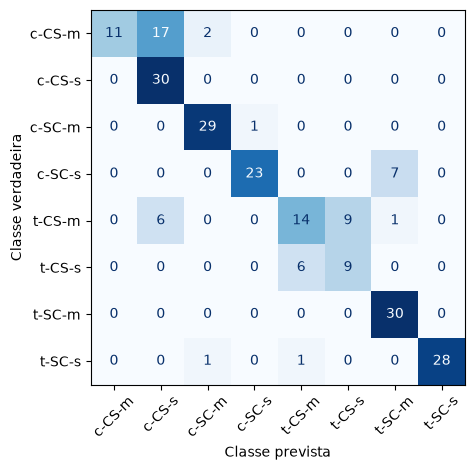

In [18]:
# Matriz de confusão: regressão logística (Fig. 3)
ConfusionMatrixDisplay.from_estimator(gs_lr, X_teste, y_teste,
                                      xticks_rotation=45, cmap="Blues", colorbar=False)
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.tight_layout()
plt.savefig("relatorio/figuras/mice_matriz_lr.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Fronteira de decisão: preparação (compartilhada pelos dois modelos)
# 1) mesmo pré-processamento do pipeline: mediana + padronização
X_pad = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))

# 2) PCA: 77 dimensões -> 2
X2 = PCA(n_components=2).fit_transform(X_pad)

# 3) classes como números 0-7 (o contourf só aceita números)
y_cod, nomes_classes = pd.factorize(y, sort=True)

# 4) grade de 300 x 300 pontos cobrindo a área dos dados
xx, yy = np.meshgrid(
    np.linspace(X2[:, 0].min() - 1, X2[:, 0].max() + 1, 300),
    np.linspace(X2[:, 1].min() - 1, X2[:, 1].max() + 1, 300),
)
pontos_grade = np.c_[xx.ravel(), yy.ravel()]

# cores: uma por classe (a mesma nas regiões e nos pontos)
cmap = ListedColormap(plt.cm.tab10.colors[:8])

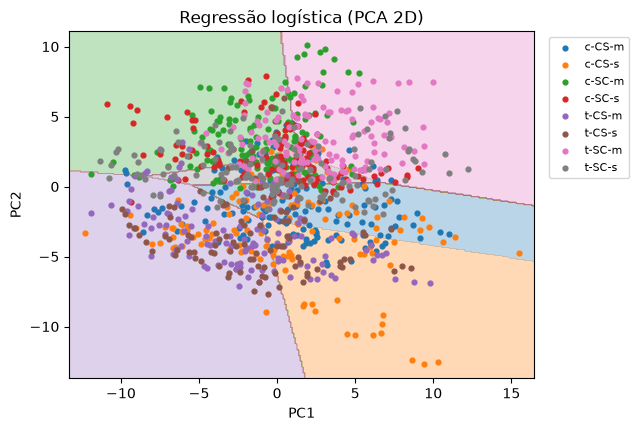

In [20]:
# Regressão logística
modelo_2d = LogisticRegression(C=gs_lr.best_params_["modelo__C"], max_iter=5000)
modelo_2d.fit(X2, y_cod)

Z = modelo_2d.predict(pontos_grade).reshape(xx.shape)

plt.figure(figsize=(6, 4.5))
plt.contourf(xx, yy, Z, levels=np.arange(-0.5, 8, 1), cmap=cmap, alpha=0.3)
for k, nome in enumerate(nomes_classes):
    mask = y_cod == k
    plt.scatter(X2[mask, 0], X2[mask, 1], color=cmap(k), s=12, label=nome)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Regressão logística (PCA 2D)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.savefig("relatorio/figuras/mice_fronteira_lr.png", dpi=150, bbox_inches="tight")
plt.show()

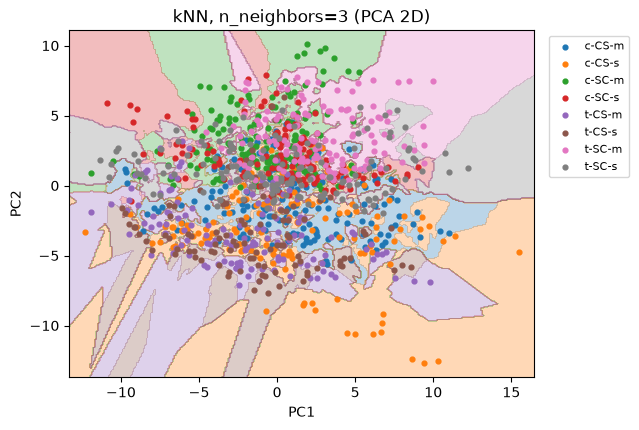

In [21]:
# kNN
k_vizinhos = gs_knn.best_params_["modelo__n_neighbors"]
modelo_2d = KNeighborsClassifier(n_neighbors=k_vizinhos)
modelo_2d.fit(X2, y_cod)

Z = modelo_2d.predict(pontos_grade).reshape(xx.shape)

plt.figure(figsize=(6, 4.5))
plt.contourf(xx, yy, Z, levels=np.arange(-0.5, 8, 1), cmap=cmap, alpha=0.3)
for k, nome in enumerate(nomes_classes):
    mask = y_cod == k
    plt.scatter(X2[mask, 0], X2[mask, 1], color=cmap(k), s=12, label=nome)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"kNN, n_neighbors={k_vizinhos} (PCA 2D)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.savefig("relatorio/figuras/mice_fronteira_knn.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Controle: divisão ingênua
Aqui as linhas são sorteadas sem olhar o animal, e a validação cruzada também. 70 dos 72 animais aparecem nos dois lados, e todos os modelos chegam a cerca de 0,99. É memória, e não generalização. O kNN escolher k=1 é a prova: o vizinho mais próximo de uma réplica é outra réplica do mesmo animal.

In [22]:
# Bloco 5: divisão ingênua (controle). Linhas sorteadas sem olhar o animal.
X_tr_ing, X_te_ing, y_tr_ing, y_te_ing = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_tr_ing.shape, X_te_ing.shape)   # esperado: (864, 77) (216, 77)

# quantos animais aparecem nos dois lados? (na divisão por animal era 0)
animais_tr = set(grupos.loc[X_tr_ing.index])
animais_te = set(grupos.loc[X_te_ing.index])
print(len(animais_tr & animais_te))     # esperado: perto de 72

(864, 77) (216, 77)
70


In [23]:
# SVM linear (divisão ingênua)
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="linear")),
])

grade = {"modelo__C": [0.1, 1, 10]}

gs_ing_svm_lin = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro")
gs_ing_svm_lin.fit(X_tr_ing, y_tr_ing)

pred = gs_ing_svm_lin.predict(X_te_ing)
print(gs_ing_svm_lin.best_params_)
print("F1 validação:", round(gs_ing_svm_lin.best_score_, 3))
print("F1 teste:", round(f1_score(y_te_ing, pred, average="macro"), 3))

{'modelo__C': 1}
F1 validação: 0.992
F1 teste: 0.996


In [24]:
# SVM RBF (divisão ingênua)
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="rbf")),
])

grade = {"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.01, 0.1]}

gs_ing_svm_rbf = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro")
gs_ing_svm_rbf.fit(X_tr_ing, y_tr_ing)

pred = gs_ing_svm_rbf.predict(X_te_ing)
print(gs_ing_svm_rbf.best_params_)
print("F1 validação:", round(gs_ing_svm_rbf.best_score_, 3))
print("F1 teste:", round(f1_score(y_te_ing, pred, average="macro"), 3))

{'modelo__C': 10, 'modelo__gamma': 'scale'}
F1 validação: 0.995
F1 teste: 0.996


In [25]:
# Regressão logística (divisão ingênua)
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=5000)),
])

grade = {"modelo__C": [0.01, 0.1, 1, 10]}

gs_ing_lr = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro")
gs_ing_lr.fit(X_tr_ing, y_tr_ing)

pred = gs_ing_lr.predict(X_te_ing)
print(gs_ing_lr.best_params_)
print("F1 validação:", round(gs_ing_lr.best_score_, 3))
print("F1 teste:", round(f1_score(y_te_ing, pred, average="macro"), 3))

{'modelo__C': 10}
F1 validação: 0.992
F1 teste: 0.986


In [26]:
# kNN (divisão ingênua)
pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", KNeighborsClassifier()),
])

grade = {"modelo__n_neighbors": [1, 3, 5, 11, 21, 51]}

gs_ing_knn = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro")
gs_ing_knn.fit(X_tr_ing, y_tr_ing)

pred = gs_ing_knn.predict(X_te_ing)
print(gs_ing_knn.best_params_)
print("F1 validação:", round(gs_ing_knn.best_score_, 3))
print("F1 teste:", round(f1_score(y_te_ing, pred, average="macro"), 3))

{'modelo__n_neighbors': 1}
F1 validação: 0.988
F1 teste: 0.991


## 7. Significância
O teste tem só 15 animais, então o F1 tem incerteza. O bootstrap sorteia animais, e não linhas, porque as 15 réplicas de um animal não são independentes. Cada sorteio vale para os quatro modelos (bootstrap pareado), e a diferença em relação à regressão logística é significativa se o intervalo de 95% não contiver zero. Resultado: só o kNN é claramente pior; os dois SVMs não se distinguem da regressão logística com 15 animais. Não usamos o McNemar porque ele supõe linhas independentes.

In [27]:
# Bloco 6: bootstrap por animal. Preparação
y_te = y_teste.to_numpy()
g_te = grupos.iloc[idx_teste].to_numpy()   # animal de cada linha do teste
animais = pd.unique(g_te)                  # os 15 animais do teste
print(len(animais))                        # esperado: 15

preds = {
    "SVM linear": gs_svm_lin.predict(X_teste),
    "SVM RBF": gs_svm_rbf.predict(X_teste),
    "Regressão logística": gs_lr.predict(X_teste),
    "kNN": gs_knn.predict(X_teste),
}

15


In [28]:
# Bootstrap: 1000 sorteios de 15 animais com reposição.
# O mesmo sorteio vale para os quatro modelos (bootstrap pareado).
rng = np.random.RandomState(42)
n_boot = 1000
f1_boot = {nome: [] for nome in preds}

for _ in range(n_boot):
    sorteio = rng.choice(animais, len(animais))                      # animais, com reposição
    pos = np.concatenate([np.where(g_te == a)[0] for a in sorteio])  # linhas desses animais
    y_s = y_te[pos]
    for nome, p in preds.items():
        f1_boot[nome].append(
            f1_score(y_s, p[pos], labels=np.unique(y_s), average="macro", zero_division=0)
        )

In [29]:
# Intervalos de 95% do F1 de cada modelo
for nome, valores in f1_boot.items():
    f1_pontual = f1_score(y_te, preds[nome], average="macro")
    inf, sup = np.percentile(valores, [2.5, 97.5])
    print(f"{nome}: F1 = {f1_pontual:.3f}  IC95% = [{inf:.3f}, {sup:.3f}]")

# Diferença pareada: cada modelo menos a regressão logística
print()
f1_lr = np.array(f1_boot["Regressão logística"])
for nome in preds:
    if nome == "Regressão logística":
        continue
    dif = np.array(f1_boot[nome]) - f1_lr
    inf, sup = np.percentile(dif, [2.5, 97.5])
    veredito = "significativa" if (inf > 0 or sup < 0) else "não significativa (contém 0)"
    print(f"{nome} - LR: dif média = {dif.mean():.3f}  IC95% = [{inf:.3f}, {sup:.3f}]  -> {veredito}")

SVM linear: F1 = 0.670  IC95% = [0.473, 0.881]
SVM RBF: F1 = 0.659  IC95% = [0.487, 0.878]
Regressão logística: F1 = 0.749  IC95% = [0.588, 0.900]
kNN: F1 = 0.451  IC95% = [0.286, 0.647]

SVM linear - LR: dif média = -0.071  IC95% = [-0.190, 0.058]  -> não significativa (contém 0)
SVM RBF - LR: dif média = -0.078  IC95% = [-0.217, 0.076]  -> não significativa (contém 0)
kNN - LR: dif média = -0.288  IC95% = [-0.434, -0.142]  -> significativa


## 8. Quais proteínas importam?
A informação mútua, calculada só no treino, ordena as proteínas pela informação que dão sobre a classe. Selecionar as melhores ajuda o kNN (F1 de validação de 0,406 para 0,491), mas o lasso mostra que a regressão logística não ganha com isso: o melhor modelo usa as 77 proteínas, e forçar poucas derruba o F1. A regressão logística já dá peso pequeno às irrelevantes, enquanto o kNN soma todas na distância com a mesma importância, por isso só ele se beneficia de removê-las.

SOD1_N          0.848
pPKCG_N         0.711
pERK_N          0.708
BRAF_N          0.614
CaNA_N          0.605
DYRK1A_N        0.603
AcetylH3K9_N    0.480
ITSN1_N         0.463
P38_N           0.457
ARC_N           0.402
dtype: float64


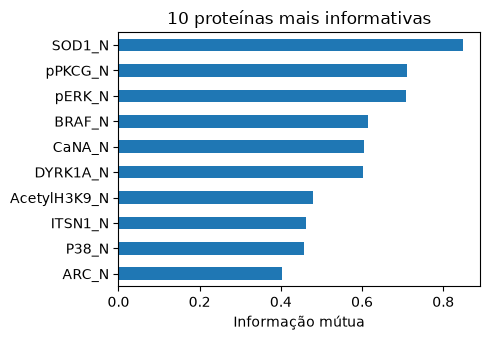

In [30]:
# 7a: proteínas mais informativas (informação mútua, calculada só no treino)
X_imp = SimpleImputer(strategy="median").fit_transform(X_treino)

mi_scores = pd.Series(
    mutual_info_classif(X_imp, y_treino, random_state=42),
    index=X.columns,
).sort_values(ascending=False)

print(mi_scores.head(10).round(3))

plt.figure(figsize=(5, 3.5))
mi_scores.head(10)[::-1].plot.barh()
plt.xlabel("Informação mútua")
plt.title("10 proteínas mais informativas")
plt.tight_layout()
plt.savefig("relatorio/figuras/mice_informacao_mutua.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
# 7b: kNN com seleção das k melhores proteínas (dentro do pipeline)
def mi(X, y):
    return mutual_info_classif(X, y, random_state=42)


pipe = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("selecao", SelectKBest(score_func=mi)),
    ("modelo", KNeighborsClassifier()),
])

grade = {
    "selecao__k": [5, 10, 20, 40, 77],
    "modelo__n_neighbors": [1, 3, 5, 11, 21],
}

gs_knn_sel = GridSearchCV(pipe, grade, cv=sgkf, scoring="f1_macro")
gs_knn_sel.fit(X_treino, y_treino, groups=g_treino)

pred = gs_knn_sel.predict(X_teste)
print(gs_knn_sel.best_params_)   # esperado: selecao__k=40, n_neighbors=5
print("F1 validação:", round(gs_knn_sel.best_score_, 3), "| antes:", round(gs_knn.best_score_, 3))
print("F1 teste:", round(f1_score(y_teste, pred, average="macro"), 3),
      "| antes:", round(f1_score(y_teste, gs_knn.predict(X_teste), average="macro"), 3))

{'modelo__n_neighbors': 5, 'selecao__k': 40}
F1 validação: 0.491 | antes: 0.406
F1 teste: 0.495 | antes: 0.451


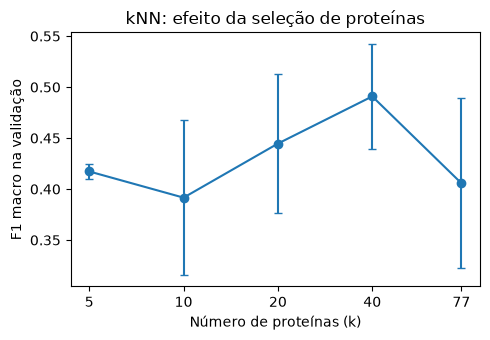

In [32]:
# F1 de validação em função do número de proteínas (barras: desvio entre as 5 dobras)
res = pd.DataFrame(gs_knn_sel.cv_results_)
melhor = res.loc[res.groupby("param_selecao__k")["mean_test_score"].idxmax()]   # melhor linha de cada k
ks = melhor["param_selecao__k"].astype(int).to_numpy()

plt.figure(figsize=(5, 3.5))
plt.errorbar(ks, melhor["mean_test_score"], yerr=melhor["std_test_score"], marker="o", capsize=3)
plt.xscale("log")
plt.xticks(ks, ks)
plt.minorticks_off()
plt.xlabel("Número de proteínas (k)")
plt.ylabel("F1 macro na validação")
plt.title("kNN: efeito da seleção de proteínas")
plt.tight_layout()
plt.savefig("relatorio/figuras/mice_knn_selecao.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
# 7c: regressão logística L2 (saga)
pipe_l2 = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(solver="saga", l1_ratio=0, max_iter=20000, random_state=42)),
])

grade_l2 = {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]}

gs_l2 = GridSearchCV(pipe_l2, grade_l2, cv=sgkf, scoring="f1_macro")
gs_l2.fit(X_treino, y_treino, groups=g_treino)

pred = gs_l2.predict(X_teste)
coef = gs_l2.best_estimator_.named_steps["modelo"].coef_     # 8 classes x 77 proteínas
usadas = (np.abs(coef).sum(axis=0) > 1e-8).sum()           # proteínas com peso != 0 em alguma classe

print(gs_l2.best_params_)
print("F1 validação:", round(gs_l2.best_score_, 3))
print("F1 teste:", round(f1_score(y_teste, pred, average="macro"), 3))
print("Proteínas usadas:", usadas)

{'modelo__C': 3}
F1 validação: 0.535
F1 teste: 0.732
Proteínas usadas: 77


In [34]:
# 7c: regressão logística L1 (lasso)
pipe_l1 = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(solver="saga", l1_ratio=1, max_iter=20000, random_state=42)),
])

grade_l1 = {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]}

gs_l1 = GridSearchCV(pipe_l1, grade_l1, cv=sgkf, scoring="f1_macro")
gs_l1.fit(X_treino, y_treino, groups=g_treino)

pred = gs_l1.predict(X_teste)
coef = gs_l1.best_estimator_.named_steps["modelo"].coef_     # 8 classes x 77 proteínas
usadas = (np.abs(coef).sum(axis=0) > 1e-8).sum()           # proteínas com peso != 0 em alguma classe

print(gs_l1.best_params_)
print("F1 validação:", round(gs_l1.best_score_, 3))
print("F1 teste:", round(f1_score(y_teste, pred, average="macro"), 3))
print("Proteínas usadas:", usadas)

{'modelo__C': 100}
F1 validação: 0.527
F1 teste: 0.706
Proteínas usadas: 77


     C  proteínas  F1 validação
  0.01         12         0.081
  0.03         39         0.383
  0.10         62         0.461
  0.30         68         0.458
  1.00         72         0.442
  3.00         76         0.460
 10.00         77         0.485
 30.00         77         0.519
100.00         77         0.527


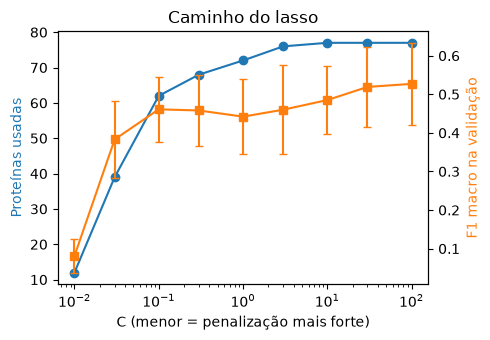

In [35]:
# Caminho do lasso: proteínas usadas e F1 de validação para cada C
caminho = []
for c in grade_l1["modelo__C"]:
    modelo_c = clone(pipe_l1).set_params(modelo__C=c).fit(X_treino, y_treino)
    coef_c = modelo_c.named_steps["modelo"].coef_
    caminho.append((c, (np.abs(coef_c).sum(axis=0) > 1e-8).sum()))

tabela = pd.DataFrame(caminho, columns=["C", "proteínas"])
tabela["F1 validação"] = gs_l1.cv_results_["mean_test_score"].round(3)   # mesma ordem da grade
print(tabela.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(5, 3.5))
ax1.plot(tabela["C"], tabela["proteínas"], marker="o", color="tab:blue")
ax1.set_xscale("log")
ax1.set_xlabel("C (menor = penalização mais forte)")
ax1.set_ylabel("Proteínas usadas", color="tab:blue")
ax2 = ax1.twinx()
ax2.errorbar(tabela["C"], tabela["F1 validação"], yerr=gs_l1.cv_results_["std_test_score"],
             marker="s", color="tab:orange", capsize=3)   # barras: desvio entre as 5 dobras
ax2.set_ylabel("F1 macro na validação", color="tab:orange")
plt.title("Caminho do lasso")
plt.tight_layout()
plt.savefig("relatorio/figuras/mice_lasso.png", dpi=150, bbox_inches="tight")
plt.show()

                     Acurácia  Precisão  Revocação     F1
SVM linear              0.724     0.699      0.679  0.670
SVM RBF                 0.724     0.664      0.679  0.659
Regressão logística     0.773     0.798      0.762  0.749
kNN                     0.502     0.452      0.471  0.451


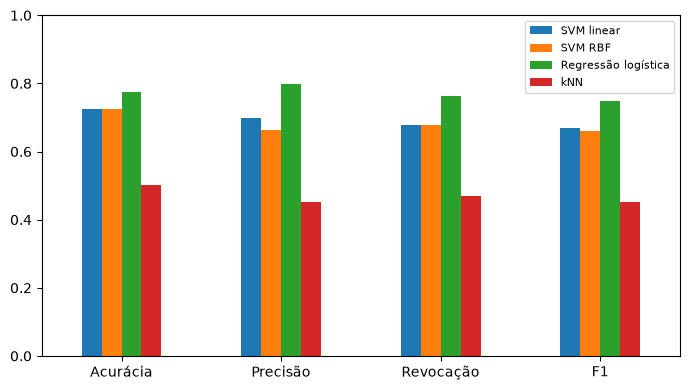

In [36]:
# Figura 5 (Mice): métricas macro de cada modelo no teste (divisão por animal)
linhas = {}
for m, p in preds.items():
    linhas[m] = {
        "Acurácia": accuracy_score(y_te, p),
        "Precisão": precision_score(y_te, p, average="macro", zero_division=0),
        "Revocação": recall_score(y_te, p, average="macro", zero_division=0),
        "F1": f1_score(y_te, p, average="macro", zero_division=0),
    }
metricas = pd.DataFrame(linhas).T      # uma linha por modelo, uma coluna por métrica
print(metricas.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
metricas.T.plot.bar(ax=ax)             # .T: métricas no eixo x, uma barra por modelo
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("relatorio/figuras/mice_painel.png", dpi=150, bbox_inches="tight")
plt.show()